# FEP Visuomotor Joystick Analysis

This notebook tests whether behavior from the FEP joystick task is **consistent with** the progression:

**prior expectation → violated prediction → prediction error → inference of hidden mapping → behavioral adaptation**

It does **not** treat behavioral adaptation as proof of the Free Energy Principle. Similar signatures can also arise from ordinary error-based motor learning.

### Main predictions

1. **Unexpected mapping switches should carry a behavioral cost**
   - longer reaction / movement / total time
   - worse initial movement direction
   - less efficient cursor trajectories

2. **That cost should shrink after a switch**
   - behavior should improve as `TrialsSinceMappingSwitch` increases

3. **Prior strength should matter**
   - an inverted trial should be more disruptive in the 90/10 strong-normal block than in the 50/50 balanced block

4. **Sensory reliability should matter**
   - low-reliability trials should contain more display noise
   - unreliable evidence may worsen inference and increase reliance on the prior

5. **The fixed transition blocks should show re-inference**
   - Block 2: early unexpected inversion should be worse than later inverted trials
   - Block 3: early return-to-normal should be worse than later normal trials


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from BCI2000Tools.FileReader import bcistream

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# Change only this path.
DAT_PATH = Path(
    r"C:\Users\gabri\Desktop\joystick_test_env\python_da\test_data\FEP\NameS001R02.dat"
)

RNG_SEED = 7


## 1. Load the BCI2000 file and inspect states


In [2]:
stream = bcistream(str(DAT_PATH))
state_names = list(stream.statedefs.keys())

print(f"Found {len(state_names)} states:\n")
for state in state_names:
    print(state)

_, states = stream.decode(
    nsamp="all",
    states=state_names
)

states_df = pd.DataFrame({
    name: np.asarray(states[name]).ravel()
    for name in state_names
})

print(f"\nSamples: {len(states_df):,}")
print(f"States:  {len(states_df.columns)}")
display(states_df.head())


Found 49 states:

Notes
JoystickXpos
JoystickYpos
JoystickZpos
JoystickButtons1
JoystickButtons2
JoystickButtons3
JoystickButtons4
JoystickButtons9
JoystickButtons10
Recording
SourceTime
SourceChannel1
FilePart
Running
PreStimulusTime
StimulusTime
PresentationRequested
PresentationDisplayed
PresentationTime
PresentationFrame
AudioBufferTime
AudioPresentationTime
VideoStimulusFrame
CursorX
CursorY
DisplayedCursorX
DisplayedCursorY
TaskPhase
TaskCondition
TargetAngle
TargetX
TargetY
TaskBlock
TaskTrial
MovementStarted
TargetHit
TrialReset
MappingSwitch
TrialsSinceMappingSwitch
PriorCondition
SensoryReliability
ReactionTimeMs
MovementTimeMs
TotalTimeMs
__pad0
__pad1
__pad2
__pad3

Samples: 5,592,224
States:  49


,Notes,JoystickXpos,JoystickYpos,JoystickZpos,JoystickButtons1,JoystickButtons2,JoystickButtons3,JoystickButtons4,JoystickButtons9,JoystickButtons10,Recording,SourceTime,SourceChannel1,FilePart,Running,PreStimulusTime,StimulusTime,PresentationRequested,PresentationDisplayed,PresentationTime,PresentationFrame,AudioBufferTime,AudioPresentationTime,VideoStimulusFrame,CursorX,CursorY,DisplayedCursorX,DisplayedCursorY,TaskPhase,TaskCondition,TargetAngle,TargetX,TargetY,TaskBlock,TaskTrial,MovementStarted,TargetHit,TrialReset,MappingSwitch,TrialsSinceMappingSwitch,PriorCondition,SensoryReliability,ReactionTimeMs,MovementTimeMs,TotalTimeMs,__pad0,__pad1,__pad2,__pad3
0,0,16383,16383,0,0,0,0,0,0,0,1,5906,2147483781,1,1,0,0,0,0,0,0,0,0,4294967295,512,512,512,512,0,0,0,512,512,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1107296256
1,0,16383,16383,0,0,0,0,0,0,0,1,5906,2147483729,1,1,0,0,0,0,0,0,0,0,4294967295,512,512,512,512,0,0,0,512,512,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,33554432
2,0,16383,16383,0,0,0,0,0,0,0,1,5906,2147483771,1,1,0,0,0,0,0,0,0,0,4294967295,512,512,512,512,0,0,0,512,512,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,16383,16383,0,0,0,0,0,0,0,1,5906,2147483797,1,1,0,0,0,0,0,0,0,0,4294967295,512,512,512,512,0,0,0,512,512,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,16383,16383,0,0,0,0,0,0,0,1,5906,2147483590,1,1,0,0,0,0,0,0,0,0,4294967295,512,512,512,512,0,0,0,512,512,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3321888768


## 2. Identify populated and empty states

A state is called populated here if it contains at least one non-zero, non-NaN value. This is only a recording-quality check because zero can be a valid task value.


In [3]:
populated_states = []
empty_states = []

for state in states_df.columns:
    values = states_df[state]
    has_data = values.notna().any() and (values.fillna(0) != 0).any()

    if has_data:
        populated_states.append(state)
    else:
        empty_states.append(state)

print("POPULATED STATES:")
for state in populated_states:
    print(state)

print("\nEMPTY / ALL-ZERO STATES:")
for state in empty_states:
    print(state)


POPULATED STATES:
JoystickXpos
JoystickYpos
JoystickButtons1
Recording
SourceTime
SourceChannel1
FilePart
Running
PreStimulusTime
StimulusTime
PresentationRequested
PresentationDisplayed
PresentationTime
PresentationFrame
AudioBufferTime
AudioPresentationTime
VideoStimulusFrame
CursorX
CursorY
DisplayedCursorX
DisplayedCursorY
TaskPhase
TaskCondition
TargetAngle
TargetX
TargetY
TaskBlock
TaskTrial
MovementStarted
TargetHit
MappingSwitch
TrialsSinceMappingSwitch
PriorCondition
SensoryReliability
ReactionTimeMs
MovementTimeMs
TotalTimeMs
__pad3

EMPTY / ALL-ZERO STATES:
Notes
JoystickZpos
JoystickButtons2
JoystickButtons3
JoystickButtons4
JoystickButtons9
JoystickButtons10
TrialReset
__pad0
__pad1
__pad2


## 3. Decode the task states

State coding from the task:

- `TaskCondition`: 0 = Normal, 1 = Inverted
- `PriorCondition`: 0 = Fixed, 1 = Hidden Mixed, 2 = Strong Normal, 3 = Balanced
- `SensoryReliability`: 0 = High, 1 = Low
- `TaskPhase`: 1 = Waiting for center, 2 = Holding center, 3 = Warning, 4 = Pre-target delay, 5 = Target visible, 6 = Feedback, 7 = Finished
- `MappingSwitch`: event associated with entry into a trial whose mapping differs from the previous trial
- `TrialsSinceMappingSwitch`: 0 on the first trial after a mapping switch


In [4]:
REQUIRED = [
    "CursorX", "CursorY", "DisplayedCursorX", "DisplayedCursorY",
    "TaskPhase", "TaskCondition", "TargetX", "TargetY",
    "TaskBlock", "TaskTrial", "MovementStarted", "TargetHit",
    "MappingSwitch", "TrialsSinceMappingSwitch", "PriorCondition",
    "SensoryReliability", "ReactionTimeMs", "MovementTimeMs", "TotalTimeMs"
]

missing = [s for s in REQUIRED if s not in states_df.columns]
if missing:
    raise KeyError(f"Required task states are missing: {missing}")

MAPPING_LABEL = {0: "Normal", 1: "Inverted"}
PRIOR_LABEL = {
    0: "Fixed",
    1: "Hidden Mixed",
    2: "Strong Normal",
    3: "Balanced",
}
RELIABILITY_LABEL = {0: "High", 1: "Low"}

def first_mode(series):
    mode = series.dropna().mode()
    return mode.iloc[0] if len(mode) else np.nan

valid_samples = states_df[
    (states_df["TaskTrial"] > 0) &
    (states_df["TaskBlock"].between(1, 6))
].copy()

print(f"Task samples retained: {len(valid_samples):,}")


Task samples retained: 5,592,192


## 4. Build one row per trial

Timing states are written at target acquisition and remain available during feedback, so the trial table takes the maximum timing value within each trial.

`TaskTrial` is global across the run. `BlockTrial` is reconstructed within each block.


In [5]:
trial_rows = []

for trial_id, g in valid_samples.groupby("TaskTrial", sort=True):
    trial_rows.append({
        "TaskTrial": int(trial_id),
        "TaskBlock": int(first_mode(g["TaskBlock"])),
        "TaskCondition": int(first_mode(g["TaskCondition"])),
        "PriorCondition": int(first_mode(g["PriorCondition"])),
        "SensoryReliability": int(first_mode(g["SensoryReliability"])),
        "MappingSwitch": int(g["MappingSwitch"].max()),
        "TrialsSinceMappingSwitch": int(first_mode(g["TrialsSinceMappingSwitch"])),
        "TargetHit": int(g["TargetHit"].max()),
        "ReactionTimeMs": float(g["ReactionTimeMs"].max()),
        "MovementTimeMs": float(g["MovementTimeMs"].max()),
        "TotalTimeMs": float(g["TotalTimeMs"].max()),
        "TargetX": float(first_mode(g["TargetX"])),
        "TargetY": float(first_mode(g["TargetY"])),
    })

trials = pd.DataFrame(trial_rows).sort_values("TaskTrial").reset_index(drop=True)
trials["BlockTrial"] = trials.groupby("TaskBlock").cumcount() + 1

trials["Mapping"] = trials["TaskCondition"].map(MAPPING_LABEL)
trials["Prior"] = trials["PriorCondition"].map(PRIOR_LABEL)
trials["Reliability"] = trials["SensoryReliability"].map(RELIABILITY_LABEL)

for metric in ["ReactionTimeMs", "MovementTimeMs", "TotalTimeMs"]:
    trials.loc[trials["TargetHit"] == 0, metric] = np.nan
    trials.loc[trials[metric] <= 0, metric] = np.nan

print(f"Trials reconstructed: {len(trials)}")
display(trials.head(10))


Trials reconstructed: 45


,TaskTrial,TaskBlock,TaskCondition,PriorCondition,SensoryReliability,MappingSwitch,TrialsSinceMappingSwitch,TargetHit,ReactionTimeMs,MovementTimeMs,TotalTimeMs,TargetX,TargetY,BlockTrial,Mapping,Prior,Reliability
0,1,1,0,0,0,0,0,1,2134.0,1013.0,3146.0,581.0,190.0,1,Normal,Fixed,High
1,2,1,0,0,0,0,1,1,699.0,897.0,1596.0,504.0,846.0,2,Normal,Fixed,High
2,3,1,0,0,0,0,2,1,688.0,692.0,1380.0,504.0,177.0,3,Normal,Fixed,High
3,4,1,0,0,0,0,3,1,497.0,580.0,1077.0,663.0,245.0,4,Normal,Fixed,High
4,5,1,0,0,0,0,4,1,589.0,493.0,1081.0,344.0,263.0,5,Normal,Fixed,High
5,6,1,0,0,0,0,5,1,537.0,584.0,1122.0,761.0,482.0,6,Normal,Fixed,High
6,7,1,0,0,0,0,6,1,553.0,1172.0,1725.0,558.0,840.0,7,Normal,Fixed,High
7,8,1,0,0,0,0,7,1,352.0,658.0,1010.0,744.0,386.0,8,Normal,Fixed,High
8,9,1,0,0,0,0,8,1,561.0,651.0,1212.0,261.0,516.0,9,Normal,Fixed,High
9,10,1,0,0,0,0,9,1,449.0,393.0,843.0,509.0,177.0,10,Normal,Fixed,High


## 5. Sequence and manipulation checks

Expected defaults:

- Block 1: Normal baseline
- Block 2: Inverted
- Block 3: Normal
- Block 4: approximately 50/50 hidden mixed
- Block 5: approximately 90% Normal / 10% Inverted
- Block 6: approximately 50/50 balanced

Low sensory reliability is randomized only in Blocks 4 to 6 in the current task.


In [6]:
block_check = (
    trials.groupby("TaskBlock")
    .agg(
        n_trials=("TaskTrial", "size"),
        hit_rate=("TargetHit", "mean"),
        inverted_fraction=("TaskCondition", "mean"),
        low_reliability_fraction=("SensoryReliability", "mean"),
        mapping_switches=("MappingSwitch", "sum"),
    )
)

display(block_check.round(3))

print("\nCounts by block × mapping × reliability:")
display(pd.crosstab(
    [trials["TaskBlock"], trials["Mapping"]],
    trials["Reliability"]
))

strong_inverted_n = int(
    ((trials["TaskBlock"] == 5) & (trials["TaskCondition"] == 1)).sum()
)

if strong_inverted_n < 5:
    print(
        f"\nWARNING: Block 5 contains only {strong_inverted_n} inverted trial(s). "
        "The strong-prior contradiction test will be descriptive and unstable. "
        "If that contrast is central, increase StrongPriorTrials."
    )


,n_trials,hit_rate,inverted_fraction,low_reliability_fraction,mapping_switches
TaskBlock,,,,,
1,20,1.000,0.000,0.000,0
2,5,1.000,1.000,0.000,1
3,5,1.000,0.000,0.000,1
4,15,0.933,0.533,0.533,10



Counts by block × mapping × reliability:


Reliability         High  Low
TaskBlock Mapping            
1         Normal      20    0
2         Inverted     5    0
3         Normal       5    0
4         Inverted     5    3
          Normal       2    5

## 6. Extract trajectory-level measures

Timing alone can miss the most interesting behavior. A participant may move quickly in the wrong direction and then correct.

For each trial this section measures the **true cursor trajectory** during target presentation:

- `PathLengthPx`: total cursor path length
- `PathEfficiency`: straight-line distance / actual path length; closer to 1 is better
- `MaxPerpendicularErrorPx`: largest sideways deviation from the ideal center-to-target line
- `InitialAlignment`: cosine between the first meaningful cursor movement and target direction
  - +1 = directly toward target
  - 0 = orthogonal
  - -1 = directly away from target
- `InitialOpposite`: 1 if the first meaningful cursor movement points more than 90° away from the target

The true cursor is used so imposed visual jitter is not mistaken for motor error.


In [7]:
CENTER = np.array([512.0, 512.0])
INITIAL_MOVE_THRESHOLD_PX = 20.0

def trajectory_features(g):
    # The target-hit sample is already phase 6, so retain it explicitly.
    tg = g[(g["TaskPhase"] == 5) | (g["TargetHit"] == 1)].copy()

    if len(tg) < 2:
        return {
            "PathLengthPx": np.nan,
            "PathEfficiency": np.nan,
            "MaxPerpendicularErrorPx": np.nan,
            "InitialAlignment": np.nan,
            "InitialOpposite": np.nan,
            "DisplayNoiseRMSPx": np.nan,
        }

    xy = tg[["CursorX", "CursorY"]].to_numpy(dtype=float)
    dxy = np.diff(xy, axis=0)
    path_length = np.linalg.norm(dxy, axis=1).sum()

    target = np.array([
        float(first_mode(tg["TargetX"])),
        float(first_mode(tg["TargetY"]))
    ])
    target_vec = target - CENTER
    direct_distance = np.linalg.norm(target_vec)

    if path_length > 0 and direct_distance > 0:
        path_efficiency = direct_distance / path_length
    else:
        path_efficiency = np.nan

    if direct_distance > 0:
        unit = target_vec / direct_distance
        rel = xy - CENTER
        projections = rel @ unit
        projected = np.outer(projections, unit)
        perpendicular = rel - projected
        max_perp = np.linalg.norm(perpendicular, axis=1).max()
    else:
        max_perp = np.nan

    disp = xy - CENTER
    disp_mag = np.linalg.norm(disp, axis=1)
    eligible = np.where(disp_mag >= INITIAL_MOVE_THRESHOLD_PX)[0]

    initial_alignment = np.nan
    initial_opposite = np.nan

    if len(eligible) and direct_distance > 0:
        v = disp[eligible[0]]
        denom = np.linalg.norm(v) * direct_distance

        if denom > 0:
            initial_alignment = float(np.dot(v, target_vec) / denom)
            initial_alignment = float(np.clip(initial_alignment, -1.0, 1.0))
            initial_opposite = float(initial_alignment < 0)

    true_xy = tg[["CursorX", "CursorY"]].to_numpy(dtype=float)
    display_xy = tg[["DisplayedCursorX", "DisplayedCursorY"]].to_numpy(dtype=float)
    display_noise_rms = float(
        np.sqrt(np.mean(np.sum((display_xy - true_xy) ** 2, axis=1)))
    )

    return {
        "PathLengthPx": float(path_length),
        "PathEfficiency": float(path_efficiency),
        "MaxPerpendicularErrorPx": float(max_perp),
        "InitialAlignment": initial_alignment,
        "InitialOpposite": initial_opposite,
        "DisplayNoiseRMSPx": display_noise_rms,
    }

traj_rows = []

for trial_id, g in valid_samples.groupby("TaskTrial", sort=True):
    feats = trajectory_features(g)
    feats["TaskTrial"] = int(trial_id)
    traj_rows.append(feats)

traj = pd.DataFrame(traj_rows)
trials = trials.merge(traj, on="TaskTrial", how="left")
trials["PathInefficiency"] = 1.0 - trials["PathEfficiency"]

display(
    trials[
        [
            "TaskTrial", "TaskBlock", "Mapping", "Reliability",
            "ReactionTimeMs", "MovementTimeMs",
            "PathEfficiency", "InitialAlignment",
            "InitialOpposite", "DisplayNoiseRMSPx"
        ]
    ].head(10)
)


,TaskTrial,TaskBlock,Mapping,Reliability,ReactionTimeMs,MovementTimeMs,PathEfficiency,InitialAlignment,InitialOpposite,DisplayNoiseRMSPx
0,1,1,Normal,High,2134.0,1013.0,1.010505,0.967280,0.0,0.0
1,2,1,Normal,High,699.0,897.0,1.088260,0.999662,0.0,0.0
2,3,1,Normal,High,688.0,692.0,1.098674,0.999660,0.0,0.0
3,4,1,Normal,High,497.0,580.0,0.960827,0.998697,0.0,0.0
4,5,1,Normal,High,589.0,493.0,0.957422,0.998988,0.0,0.0
5,6,1,Normal,High,537.0,584.0,0.797601,0.954461,0.0,0.0
6,7,1,Normal,High,553.0,1172.0,0.937237,0.988452,0.0,0.0
7,8,1,Normal,High,352.0,658.0,0.930079,0.958852,0.0,0.0
8,9,1,Normal,High,561.0,651.0,0.995041,0.988551,0.0,0.0
9,10,1,Normal,High,449.0,393.0,1.083012,0.999159,0.0,0.0


## 7. Verify the sensory-reliability manipulation

Low reliability should produce a larger difference between the true cursor and displayed cursor. If it does not, do not interpret reliability effects.


,count,mean,median,std
Reliability,,,,
High,7,0.000,0.000,0.0
Low,7,12.526,12.527,0.1


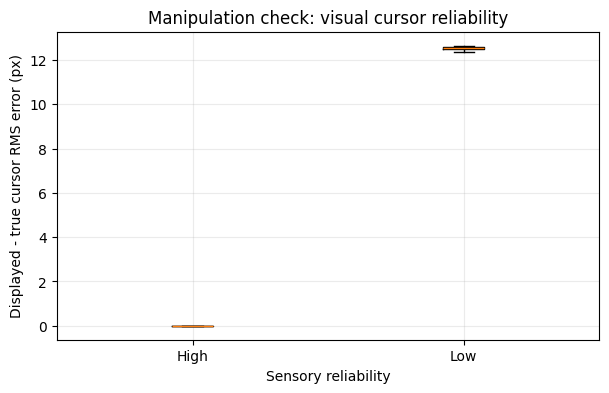

In [8]:
noise_summary = (
    trials[trials["TaskBlock"].isin([4, 5, 6])]
    .groupby("Reliability")["DisplayNoiseRMSPx"]
    .agg(["count", "mean", "median", "std"])
)

display(noise_summary.round(3))

plt.figure(figsize=(7, 4))
order = ["High", "Low"]

data = [
    trials.loc[
        (trials["TaskBlock"].isin([4, 5, 6])) &
        (trials["Reliability"] == label),
        "DisplayNoiseRMSPx"
    ].dropna().values
    for label in order
]

plt.boxplot(data, tick_labels=order)
plt.ylabel("Displayed - true cursor RMS error (px)")
plt.xlabel("Sensory reliability")
plt.title("Manipulation check: visual cursor reliability")
plt.grid(alpha=0.25)
plt.show()


## 8. Trial-by-trial overview

Dashed lines mark block changes. These plots make abrupt switch costs and later adaptation visible.


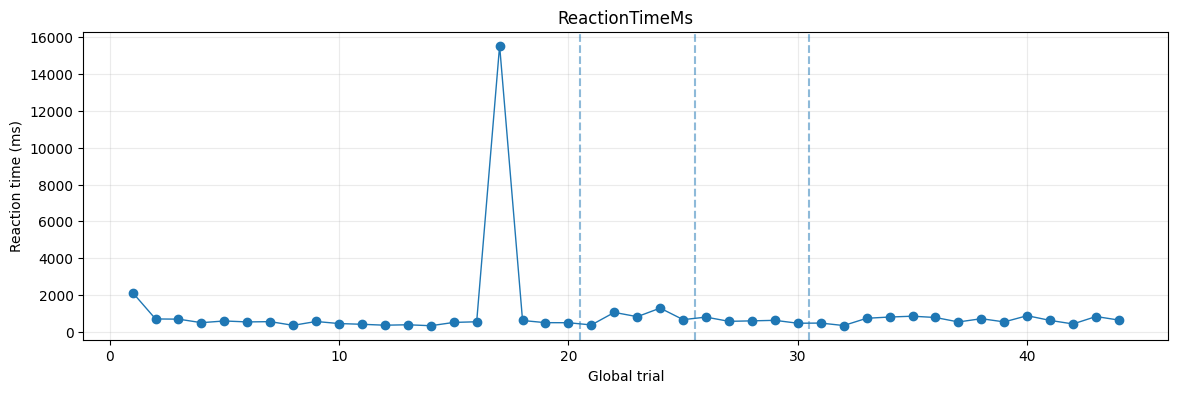

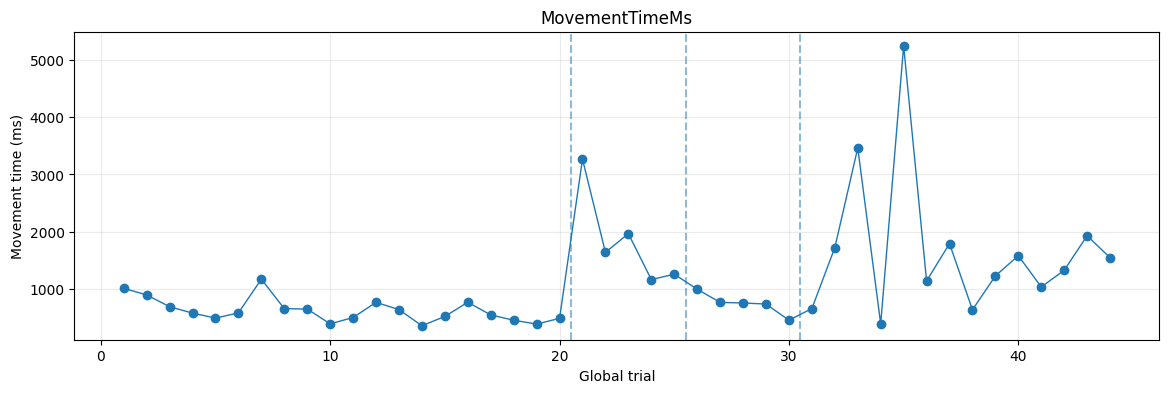

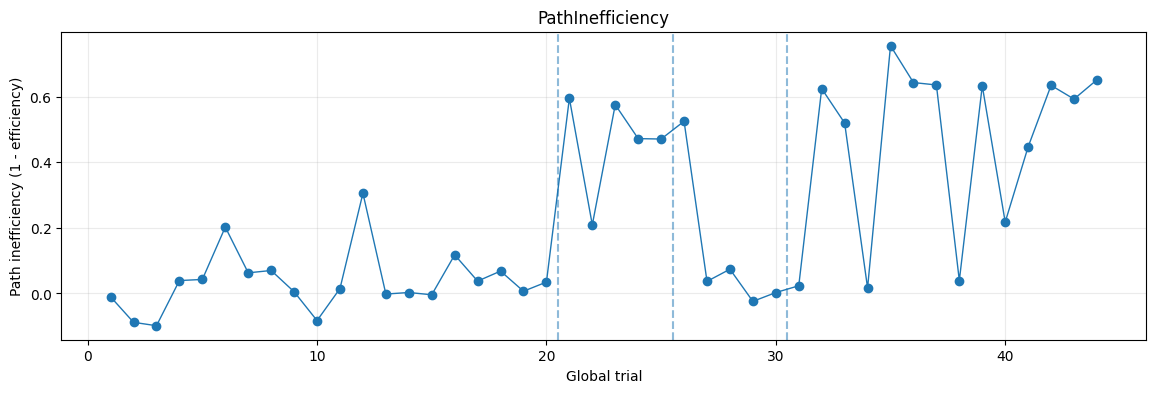

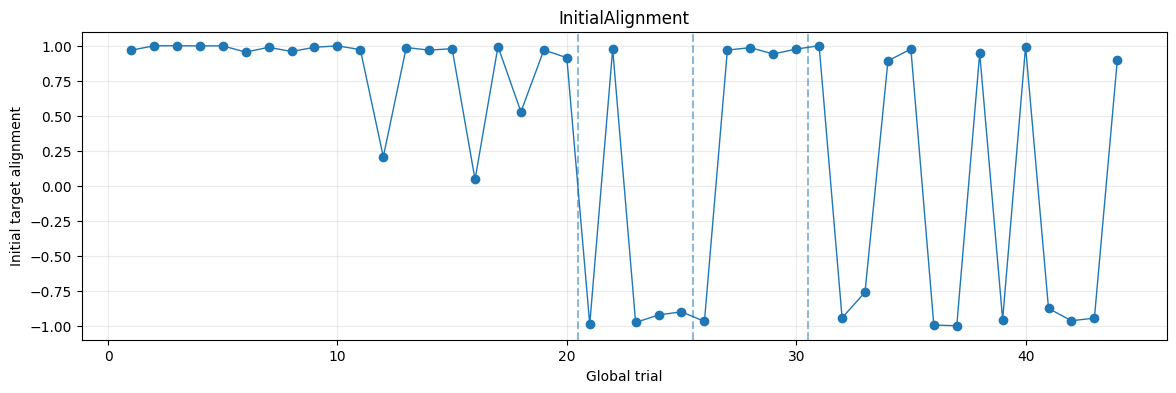

In [9]:
def plot_trial_metric(metric, ylabel=None):
    d = trials[["TaskTrial", "TaskBlock", metric]].dropna()

    plt.figure(figsize=(14, 4))
    plt.plot(d["TaskTrial"], d[metric], marker="o", linewidth=1)

    block_starts = trials.groupby("TaskBlock")["TaskTrial"].min().sort_index()
    for block, x in block_starts.items():
        if block != block_starts.index.min():
            plt.axvline(x - 0.5, linestyle="--", alpha=0.5)

    plt.xlabel("Global trial")
    plt.ylabel(ylabel or metric)
    plt.title(metric)
    plt.grid(alpha=0.25)
    plt.show()

plot_trial_metric("ReactionTimeMs", "Reaction time (ms)")
plot_trial_metric("MovementTimeMs", "Movement time (ms)")
plot_trial_metric("PathInefficiency", "Path inefficiency (1 - efficiency)")
plot_trial_metric("InitialAlignment", "Initial target alignment")


## 9. Comparison helper

For each comparison the notebook reports:

- group sample sizes
- mean difference
- bootstrap 95% confidence interval
- whether the observed direction matches the experimental prediction

A direction-only effect is weaker than a bootstrap interval that excludes zero.


In [10]:
def clean_values(series):
    return pd.to_numeric(series, errors="coerce").dropna().to_numpy(dtype=float)

def bootstrap_mean_diff(a, b, n_boot=5000, seed=RNG_SEED):
    # Difference is mean(a) - mean(b).
    a = clean_values(pd.Series(a))
    b = clean_values(pd.Series(b))

    if len(a) < 2 or len(b) < 2:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)

    for i in range(n_boot):
        aa = rng.choice(a, size=len(a), replace=True)
        bb = rng.choice(b, size=len(b), replace=True)
        diffs[i] = aa.mean() - bb.mean()

    observed = a.mean() - b.mean()
    lo, hi = np.quantile(diffs, [0.025, 0.975])

    return float(observed), float(lo), float(hi)

def effect_row(name, a, b, expected_sign, min_n=3):
    # expected_sign +1: A should be larger. -1: A should be smaller.
    a = clean_values(pd.Series(a))
    b = clean_values(pd.Series(b))

    result = {
        "Prediction": name,
        "n_A": len(a),
        "n_B": len(b),
        "Mean_A": np.mean(a) if len(a) else np.nan,
        "Mean_B": np.mean(b) if len(b) else np.nan,
        "Difference_A_minus_B": np.nan,
        "CI95_low": np.nan,
        "CI95_high": np.nan,
        "Assessment": "Insufficient data",
    }

    if len(a) < min_n or len(b) < min_n:
        return result

    diff, lo, hi = bootstrap_mean_diff(a, b)

    result["Difference_A_minus_B"] = diff
    result["CI95_low"] = lo
    result["CI95_high"] = hi

    directional = (diff * expected_sign) > 0
    robust = (
        (expected_sign > 0 and lo > 0) or
        (expected_sign < 0 and hi < 0)
    )

    if robust:
        result["Assessment"] = "FEP-consistent; bootstrap CI excludes 0"
    elif directional:
        result["Assessment"] = "Directionally FEP-consistent"
    else:
        result["Assessment"] = "Not FEP-consistent in this run"

    return result


## 10. Prediction A: mapping-switch cost

Within Blocks 4 to 6, compare the first trial after a switch with trials at least two trials removed from a switch.

Expected pattern:

- RT, MT, total time, path inefficiency, perpendicular error: **switch > stable**
- initial alignment: **switch < stable**


In [11]:
random_blocks = trials[trials["TaskBlock"].isin([4, 5, 6])].copy()

switch_trials = random_blocks[random_blocks["TrialsSinceMappingSwitch"] == 0]
stable_trials = random_blocks[random_blocks["TrialsSinceMappingSwitch"] >= 2]

switch_results = []

for metric, expected_sign in [
    ("ReactionTimeMs", +1),
    ("MovementTimeMs", +1),
    ("TotalTimeMs", +1),
    ("PathInefficiency", +1),
    ("MaxPerpendicularErrorPx", +1),
    ("InitialAlignment", -1),
]:
    switch_results.append(
        effect_row(
            f"Switch cost: {metric}",
            switch_trials[metric],
            stable_trials[metric],
            expected_sign=expected_sign,
        )
    )

switch_results = pd.DataFrame(switch_results)
display(switch_results.round(3))


,Prediction,n_A,n_B,Mean_A,Mean_B,Difference_A_minus_B,CI95_low,CI95_high,Assessment
0,Switch cost: ReactionTimeMs,9,1,658.444,475.000,NaN,NaN,NaN,Insufficient data
1,Switch cost: MovementTimeMs,9,1,1222.000,659.000,NaN,NaN,NaN,Insufficient data
2,Switch cost: TotalTimeMs,9,1,1880.222,1134.000,NaN,NaN,NaN,Insufficient data
3,Switch cost: PathInefficiency,9,1,0.428,0.023,NaN,NaN,NaN,Insufficient data
4,Switch cost: MaxPerpendicularErrorPx,9,1,56.621,28.498,NaN,NaN,NaN,Insufficient data
5,Switch cost: InitialAlignment,9,1,-0.316,1.000,NaN,NaN,NaN,Insufficient data


## 11. Prediction B: adaptation after a switch

If the participant infers the new hidden mapping, behavioral cost should decline as `TrialsSinceMappingSwitch` increases.

Expected:

- cost metrics: negative correlation
- initial alignment: positive correlation


,Metric,n,Correlation_r,Expected,Assessment
0,ReactionTimeMs,14,-0.256,negative,Directionally FEP-consistent
1,MovementTimeMs,14,0.005,negative,Not FEP-consistent in this run
2,PathInefficiency,14,-0.315,negative,Directionally FEP-consistent
3,MaxPerpendicularErrorPx,14,-0.157,negative,Directionally FEP-consistent
4,InitialAlignment,14,0.370,positive,Directionally FEP-consistent


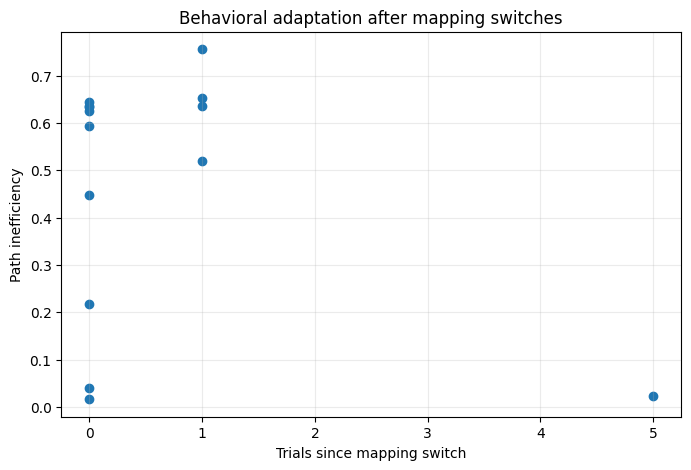

In [12]:
def correlation_with_trials_since_switch(metric):
    d = random_blocks[
        ["TrialsSinceMappingSwitch", metric]
    ].dropna()

    if len(d) < 4 or d["TrialsSinceMappingSwitch"].nunique() < 2:
        return np.nan, len(d)

    r = np.corrcoef(
        d["TrialsSinceMappingSwitch"].to_numpy(dtype=float),
        d[metric].to_numpy(dtype=float),
    )[0, 1]

    return float(r), len(d)

adaptation_rows = []

for metric, expected_direction in [
    ("ReactionTimeMs", "negative"),
    ("MovementTimeMs", "negative"),
    ("PathInefficiency", "negative"),
    ("MaxPerpendicularErrorPx", "negative"),
    ("InitialAlignment", "positive"),
]:
    r, n = correlation_with_trials_since_switch(metric)

    if np.isnan(r):
        assessment = "Insufficient data"
    else:
        consistent = (r < 0) if expected_direction == "negative" else (r > 0)
        assessment = (
            "Directionally FEP-consistent"
            if consistent
            else "Not FEP-consistent in this run"
        )

    adaptation_rows.append({
        "Metric": metric,
        "n": n,
        "Correlation_r": r,
        "Expected": expected_direction,
        "Assessment": assessment,
    })

adaptation_results = pd.DataFrame(adaptation_rows)
display(adaptation_results.round(3))

plt.figure(figsize=(8, 5))
d = random_blocks[
    ["TrialsSinceMappingSwitch", "PathInefficiency"]
].dropna()

plt.scatter(d["TrialsSinceMappingSwitch"], d["PathInefficiency"])
plt.xlabel("Trials since mapping switch")
plt.ylabel("Path inefficiency")
plt.title("Behavioral adaptation after mapping switches")
plt.grid(alpha=0.25)
plt.show()


## 12. Prediction C: Blocks 2 and 3 should show re-inference

- Block 2: unexpected Normal → Inverted
- Block 3: unexpected Inverted → Normal

The first two completed trials are compared with the last two completed trials. With only five default trials per block, treat this as descriptive.


In [13]:
def early_late_block(block, metric, n_edge=2):
    d = (
        trials[(trials["TaskBlock"] == block) & trials[metric].notna()]
        .sort_values("BlockTrial")
    )

    return d.head(n_edge)[metric], d.tail(n_edge)[metric]

transition_results = []

for block in [2, 3]:
    for metric, expected_sign in [
        ("ReactionTimeMs", +1),
        ("MovementTimeMs", +1),
        ("PathInefficiency", +1),
        ("MaxPerpendicularErrorPx", +1),
        ("InitialAlignment", -1),
    ]:
        early, late = early_late_block(block, metric)

        transition_results.append(
            effect_row(
                f"Block {block} early vs late: {metric}",
                early,
                late,
                expected_sign=expected_sign,
                min_n=2,
            )
        )

transition_results = pd.DataFrame(transition_results)
display(transition_results.round(3))


,Prediction,n_A,n_B,Mean_A,Mean_B,Difference_A_minus_B,CI95_low,CI95_high,Assessment
0,Block 2 early vs late: ReactionTimeMs,2,2,714.000,974.500,-260.500,-915.000,394.000,Not FEP-consistent in this run
1,Block 2 early vs late: MovementTimeMs,2,2,2453.000,1212.000,1241.000,381.000,2101.000,FEP-consistent; bootstrap CI excludes 0
2,Block 2 early vs late: PathInefficiency,2,2,0.402,0.472,-0.069,-0.263,0.124,Not FEP-consistent in this run
3,Block 2 early vs late: MaxPerpendicularErrorPx,2,2,26.357,47.951,-21.594,-37.408,-5.781,Not FEP-consistent in this run
4,Block 2 early vs late: InitialAlignment,2,2,-0.006,-0.910,0.904,-0.089,1.897,Not FEP-consistent in this run
5,Block 3 early vs late: ReactionTimeMs,2,2,684.000,545.000,139.000,-55.000,333.000,Directionally FEP-consistent
6,Block 3 early vs late: MovementTimeMs,2,2,882.000,597.000,285.000,29.000,541.000,FEP-consistent; bootstrap CI excludes 0
7,Block 3 early vs late: PathInefficiency,2,2,0.281,-0.011,0.292,0.034,0.550,FEP-consistent; bootstrap CI excludes 0
8,Block 3 early vs late: MaxPerpendicularErrorPx,2,2,34.849,28.639,6.210,-4.477,16.897,Directionally FEP-consistent
9,Block 3 early vs late: InitialAlignment,2,2,0.001,0.959,-0.958,-1.944,0.028,Directionally FEP-consistent


## 13. Prediction D: prior strength

Compare **inverted trials** in:

- Block 5: Strong Normal prior, about 10% inverted
- Block 6: Balanced prior, about 50% inverted

If prior strength matters, the same inverted mapping should be more disruptive in Block 5.

Expected:

- RT, MT, total time, path inefficiency: Block 5 > Block 6
- initial alignment: Block 5 < Block 6
- initial opposite-direction error rate: Block 5 > Block 6


In [14]:
strong_inv = trials[
    (trials["TaskBlock"] == 5) &
    (trials["TaskCondition"] == 1)
]

balanced_inv = trials[
    (trials["TaskBlock"] == 6) &
    (trials["TaskCondition"] == 1)
]

prior_results = []

for metric, expected_sign in [
    ("ReactionTimeMs", +1),
    ("MovementTimeMs", +1),
    ("TotalTimeMs", +1),
    ("PathInefficiency", +1),
    ("MaxPerpendicularErrorPx", +1),
    ("InitialAlignment", -1),
    ("InitialOpposite", +1),
]:
    prior_results.append(
        effect_row(
            f"Strong-normal vs balanced prior on inverted trials: {metric}",
            strong_inv[metric],
            balanced_inv[metric],
            expected_sign=expected_sign,
            min_n=3,
        )
    )

prior_results = pd.DataFrame(prior_results)
display(prior_results.round(3))

print(
    f"Block 5 inverted n = {len(strong_inv)}, "
    f"Block 6 inverted n = {len(balanced_inv)}"
)


,Prediction,n_A,n_B,Mean_A,Mean_B,Difference_A_minus_B,CI95_low,CI95_high,Assessment
0,Strong-normal vs balanced prior on inverted tr...,0,0,NaN,NaN,NaN,NaN,NaN,Insufficient data
1,Strong-normal vs balanced prior on inverted tr...,0,0,NaN,NaN,NaN,NaN,NaN,Insufficient data
2,Strong-normal vs balanced prior on inverted tr...,0,0,NaN,NaN,NaN,NaN,NaN,Insufficient data
3,Strong-normal vs balanced prior on inverted tr...,0,0,NaN,NaN,NaN,NaN,NaN,Insufficient data
4,Strong-normal vs balanced prior on inverted tr...,0,0,NaN,NaN,NaN,NaN,NaN,Insufficient data
5,Strong-normal vs balanced prior on inverted tr...,0,0,NaN,NaN,NaN,NaN,NaN,Insufficient data
6,Strong-normal vs balanced prior on inverted tr...,0,0,NaN,NaN,NaN,NaN,NaN,Insufficient data


Block 5 inverted n = 0, Block 6 inverted n = 0


## 14. Prediction E: sensory reliability

First test whether low reliability increases behavioral cost in Blocks 4 to 6.

This effect supports the precision-weighting idea but is not uniquely diagnostic of FEP. A stronger test is whether prior effects increase when sensory evidence is unreliable.


In [15]:
low_rel = random_blocks[random_blocks["SensoryReliability"] == 1]
high_rel = random_blocks[random_blocks["SensoryReliability"] == 0]

reliability_results = []

for metric, expected_sign in [
    ("ReactionTimeMs", +1),
    ("MovementTimeMs", +1),
    ("TotalTimeMs", +1),
    ("PathInefficiency", +1),
    ("MaxPerpendicularErrorPx", +1),
    ("InitialAlignment", -1),
]:
    reliability_results.append(
        effect_row(
            f"Low vs high sensory reliability: {metric}",
            low_rel[metric],
            high_rel[metric],
            expected_sign=expected_sign,
        )
    )

reliability_results = pd.DataFrame(reliability_results)
display(reliability_results.round(3))


,Prediction,n_A,n_B,Mean_A,Mean_B,Difference_A_minus_B,CI95_low,CI95_high,Assessment
0,Low vs high sensory reliability: ReactionTimeMs,7,7,709.714,598.429,111.286,-55.589,272.718,Directionally FEP-consistent
1,Low vs high sensory reliability: MovementTimeMs,7,7,2202.000,1184.000,1018.000,-37.579,2293.593,Directionally FEP-consistent
2,Low vs high sensory reliability: TotalTimeMs,7,7,2911.571,1782.286,1129.286,16.886,2464.182,FEP-consistent; bootstrap CI excludes 0
3,Low vs high sensory reliability: PathInefficiency,7,7,0.485,0.435,0.050,-0.220,0.326,Directionally FEP-consistent
4,Low vs high sensory reliability: MaxPerpendicu...,7,7,70.144,46.674,23.470,-9.409,62.973,Directionally FEP-consistent
5,Low vs high sensory reliability: InitialAlignment,7,7,-0.101,-0.145,0.045,-1.002,1.092,Not FEP-consistent in this run


In [16]:
interaction = (
    trials[
        (trials["TaskBlock"].isin([5, 6])) &
        (trials["TaskCondition"] == 1)
    ]
    .groupby(["TaskBlock", "Reliability"])
    .agg(
        n=("TaskTrial", "size"),
        mean_RT=("ReactionTimeMs", "mean"),
        mean_MT=("MovementTimeMs", "mean"),
        mean_path_ineff=("PathInefficiency", "mean"),
        mean_initial_alignment=("InitialAlignment", "mean"),
        opposite_error_rate=("InitialOpposite", "mean"),
    )
)

display(interaction.round(3))

if len(interaction) < 4 or interaction["n"].min() < 3:
    print(
        "\nThe prior × sensory-reliability interaction is too sparse for a "
        "stable test in this run. This is expected with only about two inverted "
        "trials in the default 90/10 block."
    )


,,n,mean_RT,mean_MT,mean_path_ineff,mean_initial_alignment,opposite_error_rate
TaskBlock,Reliability,,,,,,



The prior × sensory-reliability interaction is too sparse for a stable test in this run. This is expected with only about two inverted trials in the default 90/10 block.


## 15. Nominal mapping surprise

For the mixed-prior blocks:

- Block 4: 50/50
- Block 5: 90% Normal / 10% Inverted
- Block 6: 50/50

Define:

**surprise = -log2 P(actual mapping)**

Higher surprise should tend to accompany larger behavioral cost if prior-weighted inference is relevant.

This is a simple task-level variable, not a fitted latent-state model.


count  mean
TaskBlock Mapping              
4         Inverted      8   1.0
          Normal        7   1.0

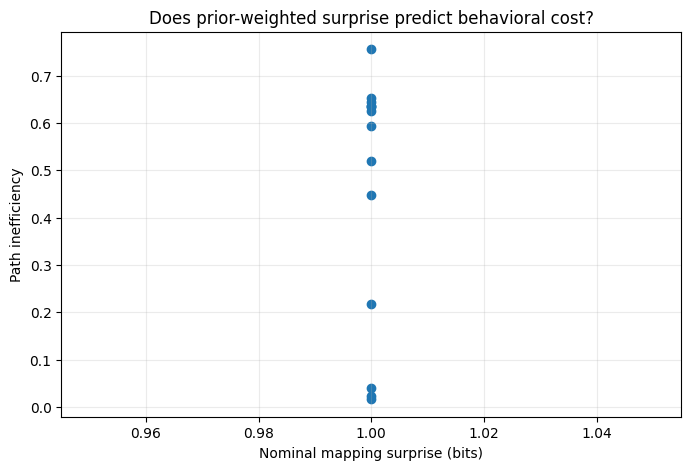

In [17]:
def nominal_mapping_probability(row):
    block = int(row["TaskBlock"])
    inverted = int(row["TaskCondition"]) == 1

    if block in [4, 6]:
        return 0.5

    if block == 5:
        return 0.1 if inverted else 0.9

    return np.nan

trials["MappingProbability"] = trials.apply(
    nominal_mapping_probability, axis=1
)

trials["SurpriseBits"] = -np.log2(trials["MappingProbability"])

display(
    trials[trials["TaskBlock"].isin([4, 5, 6])]
    .groupby(["TaskBlock", "Mapping"])["SurpriseBits"]
    .agg(["count", "mean"])
    .round(3)
)

plt.figure(figsize=(8, 5))

d = trials[
    trials["TaskBlock"].isin([4, 5, 6])
][["SurpriseBits", "PathInefficiency"]].dropna()

plt.scatter(d["SurpriseBits"], d["PathInefficiency"])
plt.xlabel("Nominal mapping surprise (bits)")
plt.ylabel("Path inefficiency")
plt.title("Does prior-weighted surprise predict behavioral cost?")
plt.grid(alpha=0.25)
plt.show()


## 16. Automated FEP-consistency summary

This summarizes directional evidence across the main comparisons.

Interpretation:

- **FEP-consistent behavioral pattern**: several predictions point in the expected direction
- **Mixed behavioral pattern**: predictions are split
- **Little FEP-consistent behavioral evidence**: few predictions appear in the expected direction

This is not a formal test of the Free Energy Principle and does not distinguish FEP from standard sensorimotor adaptation models.


In [18]:
all_assessments = pd.concat(
    [
        switch_results[["Prediction", "Assessment"]],
        transition_results[["Prediction", "Assessment"]],
        prior_results[["Prediction", "Assessment"]],
        reliability_results[["Prediction", "Assessment"]],
    ],
    ignore_index=True,
)

testable = all_assessments[
    all_assessments["Assessment"] != "Insufficient data"
].copy()

if len(testable) == 0:
    print("No predictions had enough data to evaluate.")
else:
    consistent = testable["Assessment"].str.contains(
        "FEP-consistent", regex=False
    ).sum()

    robust = testable["Assessment"].str.contains(
        "CI excludes 0", regex=False
    ).sum()

    total = len(testable)
    fraction = consistent / total

    if fraction >= 0.70:
        overall = "FEP-consistent behavioral pattern"
    elif fraction >= 0.40:
        overall = "Mixed behavioral pattern"
    else:
        overall = "Little FEP-consistent behavioral evidence in this run"

    print(f"Overall: {overall}")
    print(f"Directionally consistent predictions: {consistent}/{total}")
    print(f"Bootstrap-CI-supported predictions: {robust}/{total}")

    print(
        "\nImportant: this is a pattern summary, not a formal test of FEP "
        "and not evidence that FEP is uniquely better than standard "
        "sensorimotor adaptation models."
    )

display(all_assessments)


Overall: FEP-consistent behavioral pattern
Directionally consistent predictions: 16/16
Bootstrap-CI-supported predictions: 4/16

Important: this is a pattern summary, not a formal test of FEP and not evidence that FEP is uniquely better than standard sensorimotor adaptation models.


,Prediction,Assessment
0,Switch cost: ReactionTimeMs,Insufficient data
1,Switch cost: MovementTimeMs,Insufficient data
2,Switch cost: TotalTimeMs,Insufficient data
3,Switch cost: PathInefficiency,Insufficient data
4,Switch cost: MaxPerpendicularErrorPx,Insufficient data
5,Switch cost: InitialAlignment,Insufficient data
6,Block 2 early vs late: ReactionTimeMs,Not FEP-consistent in this run
7,Block 2 early vs late: MovementTimeMs,FEP-consistent; bootstrap CI excludes 0
8,Block 2 early vs late: PathInefficiency,Not FEP-consistent in this run
9,Block 2 early vs late: MaxPerpendicularErrorPx,Not FEP-consistent in this run


## 17. Review the final trial-level table

The notebook does **not** automatically write a CSV. The analyzed table remains available in memory as `trials`.


In [19]:
columns_to_review = [
    "TaskTrial", "TaskBlock", "BlockTrial",
    "Mapping", "Prior", "Reliability",
    "MappingSwitch", "TrialsSinceMappingSwitch",
    "TargetHit", "ReactionTimeMs", "MovementTimeMs", "TotalTimeMs",
    "PathLengthPx", "PathEfficiency", "PathInefficiency",
    "MaxPerpendicularErrorPx", "InitialAlignment", "InitialOpposite",
    "DisplayNoiseRMSPx", "SurpriseBits"
]

display(trials[columns_to_review])


,TaskTrial,TaskBlock,BlockTrial,Mapping,Prior,Reliability,MappingSwitch,TrialsSinceMappingSwitch,TargetHit,ReactionTimeMs,MovementTimeMs,TotalTimeMs,PathLengthPx,PathEfficiency,PathInefficiency,MaxPerpendicularErrorPx,InitialAlignment,InitialOpposite,DisplayNoiseRMSPx,SurpriseBits
0,1,1,1,Normal,Fixed,High,0,0,1,2134.0,1013.0,3146.0,325.886288,1.010505,-0.010505,26.191136,0.967280,0.0,0.000000,NaN
1,2,1,2,Normal,Fixed,High,0,1,1,699.0,897.0,1596.0,307.000000,1.088260,-0.088260,6.279636,0.999662,0.0,0.000000,NaN
2,3,1,3,Normal,Fixed,High,0,2,1,688.0,692.0,1380.0,305.000000,1.098674,-0.098674,6.305665,0.999660,0.0,0.000000,NaN
3,4,1,4,Normal,Fixed,High,0,3,1,497.0,580.0,1077.0,319.246948,0.960827,0.039173,17.610952,0.998697,0.0,0.000000,NaN
4,5,1,5,Normal,Fixed,High,0,4,1,589.0,493.0,1081.0,313.732898,0.957422,0.042578,20.374548,0.998988,0.0,0.000000,NaN
5,6,1,6,Normal,Fixed,High,0,5,1,537.0,584.0,1122.0,314.443719,0.797601,0.202399,43.265426,0.954461,0.0,0.000000,NaN
6,7,1,7,Normal,Fixed,High,0,6,1,553.0,1172.0,1725.0,353.389682,0.937237,0.062763,22.493289,0.988452,0.0,0.000000,NaN
7,8,1,8,Normal,Fixed,High,0,7,1,352.0,658.0,1010.0,283.854982,0.930079,0.069921,48.331946,0.958852,0.0,0.000000,NaN
8,9,1,9,Normal,Fixed,High,0,8,1,561.0,651.0,1212.0,252.282863,0.995041,0.004959,21.383739,0.988551,0.0,0.000000,NaN
9,10,1,10,Normal,Fixed,High,0,9,1,449.0,393.0,843.0,309.334863,1.083012,-0.083012,12.277120,0.999159,0.0,0.000000,NaN


## What would make the FEP interpretation more convincing?

The strongest result would be a converging pattern:

1. abrupt performance cost immediately after hidden-state changes,
2. recovery as the participant infers the new mapping,
3. larger cost for the same contradictory mapping under a stronger prior,
4. systematic modulation by sensory reliability,
5. neural signals that track switch-related surprise or uncertainty before behavioral correction.

The current states are well suited for items 1 to 4. Neural data would be needed for item 5.

### Design consideration

With 20 trials in the 90/10 block, only about two trials are inverted. If rare contradictory trials are a primary scientific contrast, increase `StrongPriorTrials` or aggregate repeated runs so the prior-effect estimate is not driven by only a few observations.
